# EDA — Phishing Email Datasets

**MSc thesis project — Akın Aydın, Liverpool John Moores University**

This notebook characterises the two corpora that will underpin the phishing-detection
framework:

- **Dataset 1** — the Kaggle multi-source phishing dataset
  (`naserabdullahalam/phishing-email-dataset`), an aggregation of six labeled corpora
  (CEAS_08, Enron, Ling-Spam, Nazario, Nigerian Fraud, SpamAssassin) plus a unified
  `phishing_email.csv`.
- **Dataset 2** — the AUEB Enron-Spam corpus (Metsis et al. 2006), the legacy
  benchmark widely used in prior spam/phishing research.

Outputs:

1. `figures/fig_class_dist_phishing.png` (§2.2)
2. `figures/fig_text_length_phishing.png` (§2.3)
3. `figures/fig_cross_dataset_length.png` (§4 — added in a later section)
4. `figures/table_dataset_summary.csv` (§5)

## 0. Setup

In [1]:
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import nltk
import numpy as np
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT / "src"))
FIGURES_DIR = PROJECT_ROOT / "figures"
FIGURES_DIR.mkdir(exist_ok=True)

from data_loader import (
    load_enron_spam,
    load_phishfuzzer,
    load_phishing_dataset,
    load_phishing_sources,
)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 200
plt.rcParams["savefig.bbox"] = "tight"

for pkg in ("stopwords", "words"):
    try:
        nltk.data.find(f"corpora/{pkg}")
    except LookupError:
        nltk.download(pkg, quiet=True)

print("Setup complete.")
print(f"Figures will be saved under: {FIGURES_DIR}")

Setup complete.
Figures will be saved under: C:\Users\<user>\msc-thesis\figures


## 1. Load datasets

Five views are loaded up-front so subsequent cells re-use the in-memory DataFrames:

- `df_phish` — `phishing_email.csv` as-is (82,486 rows). Headline statistics for §2
  use this.
- `df_phish_clean` — same minus the 29,767 Enron-origin rows (52,719 rows). Used in §4
  for the cross-dataset comparison so we do not double-count Enron emails between
  "modern" (Dataset 1) and "legacy" (Dataset 2).
- `df_phish_src` — the six per-source CSVs concatenated with source attribution; used
  for per-source heterogeneity sub-analysis.
- `df_enron` — AUEB Enron-Spam, 33,716 rows across six subsets (cached as a pickle
  after the first walk, so subsequent loads are ~0.1 s).
- `df_phf` — PhishFuzzer (Tóth et al. 2025), 23,100 rows total (3,300 seeds + 19,800
  LLM variants). Both 3-class label (`type_3class`) and binary label
  (`label`, per Decision C2 → Phishing | Spam = 1, Valid = 0) are stored. §3.5
  characterises it; the §4 cross-dataset figure uses **variants only, English only**
  (~19,164 rows) to keep the "AI-generated" signal clean of seed/Kaggle overlap.

In [2]:
from data_loader import load_phishfuzzer

df_phish = load_phishing_dataset()
df_phish_clean = load_phishing_dataset(decontaminate=True)
df_phish_src = load_phishing_sources()
df_enron = load_enron_spam()
df_phf = load_phishfuzzer()

for name, df in [
    ("df_phish", df_phish),
    ("df_phish_clean", df_phish_clean),
    ("df_phish_src", df_phish_src),
    ("df_enron", df_enron),
    ("df_phf", df_phf),
]:
    print(f"{name:18s}  rows={len(df):>7,}   cols={len(df.columns)}")

C:\Users\<user>\msc-thesis\src\data_loader.py:168: UserWarning: Enron span located at offset 0 with 99.42% label-sequence match — 174 of 29767 labels differ between Enron.csv and the corresponding rows in phishing_email.csv (Kaggle re-labeled borderline cases).
  mask = _identify_enron_rows(df, enron_labels)


df_phish            rows= 82,486   cols=2
df_phish_clean      rows= 52,719   cols=2
df_phish_src        rows= 82,486   cols=3
df_enron            rows= 33,716   cols=4
df_phf              rows= 23,100   cols=15


## 2. Dataset 1 — Kaggle multi-source phishing dataset

All headline statistics in this section use the full, non-decontaminated `df_phish`.
The `text_combined` field has already been processed by the Kaggle author
(lower-cased, punctuation stripped, common stopwords removed); we treat that as the
"Dataset 1 text" throughout this section.

### 2.1 Shape and schema

In [3]:
print("df_phish.shape:", df_phish.shape)
print()
print("dtypes:")
print(df_phish.dtypes.to_string())
print()
print("first 3 rows:")
df_phish.head(3)

df_phish.shape: (82486, 2)

dtypes:
text       str
label    int64

first 3 rows:


,text,label
0,hpl nom may 25 2001 see attached file hplno 52...,0
1,nom actual vols 24 th forwarded sabrae zajac h...,0
2,enron actuals march 30 april 1 201 estimated a...,0


### 2.2 Class distribution → `figures/fig_class_dist_phishing.png`

The dataset is roughly balanced — the phishing (positive) class is slightly larger
than the legitimate (negative) class. This is a deliberately balanced research
collection and does not reflect in-the-wild phishing-to-legitimate ratios, where
legitimate traffic typically dominates by an order of magnitude or more.

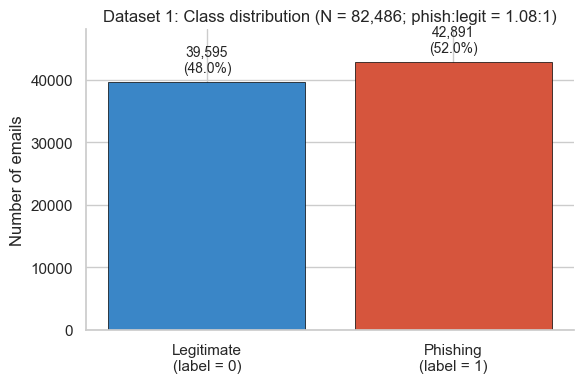

Saved → figures\fig_class_dist_phishing.png


In [4]:
counts = df_phish["label"].value_counts().sort_index()
total = int(counts.sum())
ratio_phish_to_legit = counts[1] / counts[0]
labels = ["Legitimate\n(label = 0)", "Phishing\n(label = 1)"]
colours = ["#3a86c7", "#d6553d"]

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(labels, counts.values, color=colours, edgecolor="black", linewidth=0.5)
for bar, n in zip(bars, counts.values):
    ax.annotate(
        f"{n:,}\n({n/total:.1%})",
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5), textcoords="offset points",
        ha="center", va="bottom", fontsize=10,
    )

ax.set_ylabel("Number of emails")
ax.set_title(
    f"Dataset 1: Class distribution (N = {total:,}; phish:legit = {ratio_phish_to_legit:.2f}:1)"
)
ax.set_ylim(0, counts.max() * 1.12)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

out = FIGURES_DIR / "fig_class_dist_phishing.png"
plt.savefig(out)
plt.show()
print(f"Saved → {out.relative_to(PROJECT_ROOT)}")

### 2.3 Text length distribution by class → `figures/fig_text_length_phishing.png`

Two views: token count (whitespace-separated, primary) and character count
(sanity check). Both are clipped at the 99.5th percentile so the long tail doesn't
flatten the histogram. Medians per class are overlaid as dashed lines.

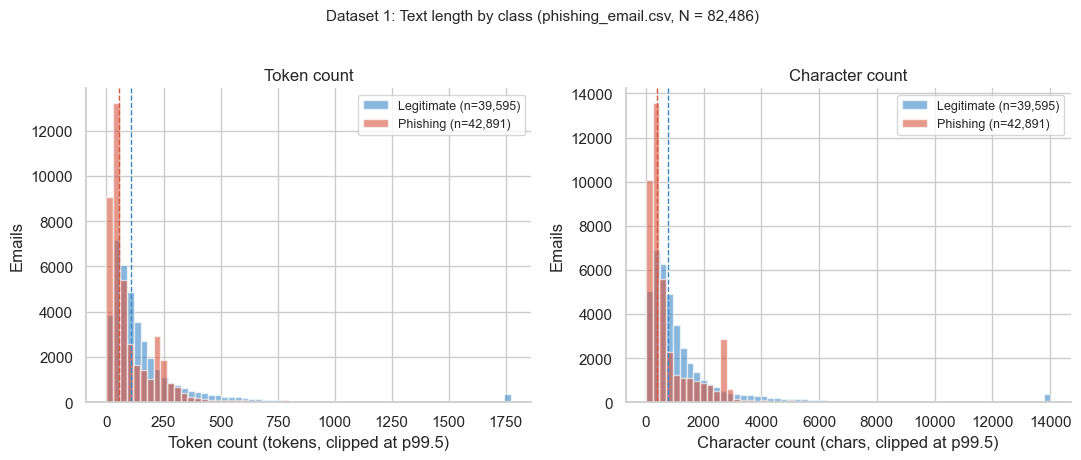

Summary statistics (length by class):
       tok_len                                                  char_len                                                        
         count   mean    std  min   25%    50%    75%       max    count    mean      std   min    25%    50%     75%        max
label                                                                                                                           
0      39595.0  203.2  479.2  2.0  57.0  106.0  203.0   23359.0  39595.0  1536.1   3695.9  11.0  411.0  779.0  1493.0   160318.0
1      42891.0  121.3  594.5  0.0  32.0   55.0  154.0  107710.0  42891.0  1060.4  21192.7   1.0  241.0  391.0  1058.0  4279526.0

Saved → figures\fig_text_length_phishing.png


In [5]:
df_phish = df_phish.assign(
    char_len=df_phish["text"].str.len(),
    tok_len=df_phish["text"].str.split().str.len(),
)

class_names = {0: "Legitimate", 1: "Phishing"}
palette = {0: "#3a86c7", 1: "#d6553d"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, col, title, unit in zip(
    axes,
    ["tok_len", "char_len"],
    ["Token count", "Character count"],
    ["tokens", "chars"],
):
    upper = df_phish[col].quantile(0.995)
    for lab, sub in df_phish.groupby("label"):
        ax.hist(
            sub[col].clip(upper=upper),
            bins=60, alpha=0.6,
            label=f"{class_names[lab]} (n={len(sub):,})",
            color=palette[lab],
        )
        ax.axvline(sub[col].median(), color=palette[lab], linestyle="--", linewidth=1)
    ax.set_xlabel(f"{title} ({unit}, clipped at p99.5)")
    ax.set_ylabel("Emails")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=9)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "Dataset 1: Text length by class (phishing_email.csv, N = 82,486)",
    fontsize=11, y=1.02,
)
plt.tight_layout()

out = FIGURES_DIR / "fig_text_length_phishing.png"
plt.savefig(out)
plt.show()

print("Summary statistics (length by class):")
print(df_phish.groupby("label")[["tok_len", "char_len"]].describe().round(1).to_string())
print(f"\nSaved → {out.relative_to(PROJECT_ROOT)}")

### 2.4 Data quality audit

Null / empty / duplicate audit. Exact-text duplicates are a real concern for the
modeling phase because they inflate held-out scores if the same email appears in
both train and test splits. We surface the count here; deduplication is a
preprocessing decision for the modeling phase, not done in EDA.

In [6]:
nulls = int(df_phish["text"].isna().sum())
empties = int((df_phish["text"].str.strip() == "").sum())
total_dups = int(df_phish.duplicated(subset=["text"]).sum())
dups_by_class = (
    df_phish.groupby("label", group_keys=False)
    .apply(lambda g: g.duplicated(subset=["text"]).sum())
    .rename("duplicate_rows")
)

print(f"Null text rows:        {nulls}")
print(f"Empty text rows:       {empties}")
print(f"Exact-duplicate rows:  {total_dups:,} ({total_dups/len(df_phish):.1%})")
print()
print("Duplicates by class:")
print(dups_by_class.to_string())

Null text rows:        0
Empty text rows:       1
Exact-duplicate rows:  408 (0.5%)

Duplicates by class:
label
0    362
1     46


### 2.5 Pattern counts per class

Counts of URLs, email addresses, phone-shaped digit sequences, and out-of-vocabulary
(OOV) tokens per class. These motivate the **Pipeline A** preprocessing decisions
(placeholder substitution, spelling correction) outlined in §4.3 of the proposal.

**Important — text source for this sub-analysis**: the `text_combined` field in
`phishing_email.csv` has already been stripped of punctuation by the Kaggle author,
so URL- and email-shaped patterns are no longer detectable in it. We therefore run
pattern detection on **raw `subject + body`** from the per-source CSVs (`df_phish_src`).
This is also the input format the Pipeline A preprocessor will see in production,
so the counts here are directly informative for design decisions.

*OOV tokens* are tokens not present in NLTK's English `words` corpus — an upper
bound on real misspellings (proper nouns and domain terms also get flagged).
OOV is computed on a stratified 5k-per-class sample to keep the cell fast.

In [7]:
URL_RX = r"https?://\S+"
EMAIL_RX = r"\b[\w.+-]+@[\w-]+\.[\w.-]+\b"
PHONE_RX = r"(?:\+?\d[\s\-().]*){8,}"

df_raw = df_phish_src.copy()
df_raw["n_urls"] = df_raw["text"].str.count(URL_RX)
df_raw["n_emails"] = df_raw["text"].str.count(EMAIL_RX)
df_raw["n_phones"] = df_raw["text"].str.count(PHONE_RX)

from nltk.corpus import words as nltk_words
ENGLISH_WORDS = {w.lower() for w in nltk_words.words()}
TOKEN_RX = re.compile(r"[A-Za-z']{2,}")

def count_oov(text):
    return sum(1 for t in TOKEN_RX.findall(text) if t.lower() not in ENGLISH_WORDS)

sample = pd.concat([
    df_raw[df_raw.label == 0].sample(5000, random_state=42),
    df_raw[df_raw.label == 1].sample(5000, random_state=42),
])
sample = sample.assign(n_oov=sample["text"].apply(count_oov))

full_counts = (
    df_raw.groupby("label")[["n_urls", "n_emails", "n_phones"]]
    .agg(["mean", "sum"])
    .round(3)
)
oov_counts = sample.groupby("label")["n_oov"].agg(["mean", "sum"]).round(2)

print("Per-class pattern counts (full dataset, raw subject+body from per-source CSVs):")
print(full_counts.to_string())
print()
print("Out-of-vocabulary token counts (stratified 5k/class sample, raw text):")
print(oov_counts.to_string())

Per-class pattern counts (full dataset, raw subject+body from per-source CSVs):
      n_urls        n_emails        n_phones       
        mean    sum     mean    sum     mean    sum
label                                              
0      1.712  67774    0.777  30767    1.324  52421
1      2.071  88837    1.312  56281    0.359  15400

Out-of-vocabulary token counts (stratified 5k/class sample, raw text):
         mean     sum
label                
0       72.30  361485
1      172.38  861905


### 2.6 Top tokens per class, with and without stopwords

Per CLAUDE.md note 2, stopword removal is treated as an **ablation variable**, not a
default. We surface the top tokens both ways so the report can reference the
discriminative-token signal regardless of which preprocessing pipeline is being
discussed.

**Text source**: same reasoning as §2.5 — `text_combined` has already had stopwords
removed by the Kaggle author, so a "with / without stopwords" comparison on it is
meaningless. We use the **raw `subject + body`** from `df_phish_src` instead. The
"with stopwords" view shows how dominant function words are in raw email text;
the "without stopwords" view reveals the topical / lexical class signature.

In [8]:
from nltk.corpus import stopwords as nltk_stopwords
EN_STOPWORDS = set(nltk_stopwords.words("english"))

def top_tokens(series, n=20, drop_stopwords=False):
    counter = Counter()
    for text in series:
        for tok in TOKEN_RX.findall(text.lower()):
            if drop_stopwords and tok in EN_STOPWORDS:
                continue
            counter[tok] += 1
    return counter.most_common(n)

legit_raw = df_phish_src.loc[df_phish_src.label == 0, "text"]
phish_raw = df_phish_src.loc[df_phish_src.label == 1, "text"]

def to_frame(per_label_top):
    col_legit = [f"{t} ({c:,})" for t, c in per_label_top[0]]
    col_phish = [f"{t} ({c:,})" for t, c in per_label_top[1]]
    return pd.DataFrame({"Legitimate (label=0)": col_legit, "Phishing (label=1)": col_phish})

top_with = {0: top_tokens(legit_raw, drop_stopwords=False),
            1: top_tokens(phish_raw, drop_stopwords=False)}
top_without = {0: top_tokens(legit_raw, drop_stopwords=True),
               1: top_tokens(phish_raw, drop_stopwords=True)}

print("Top 20 tokens — WITH stopwords (raw subject+body, df_phish_src):")
print(to_frame(top_with).to_string(index=False))
print()
print("Top 20 tokens — WITHOUT stopwords (raw subject+body, df_phish_src):")
print(to_frame(top_without).to_string(index=False))

Top 20 tokens — WITH stopwords (raw subject+body, df_phish_src):
Legitimate (label=0) Phishing (label=1)
       the (466,238)      the (236,345)
        to (309,258)       to (210,782)
       and (228,252)       of (159,481)
        of (227,858)      com (149,129)
        in (179,610)      and (147,956)
       for (128,490)      you (115,952)
        is (120,830)      cnn (113,876)
        on (102,952)       in (105,231)
       that (97,577)      your (96,853)
       this (82,888)      http (96,562)
        you (82,492)       for (79,426)
         it (79,419)      this (78,482)
         be (74,432)       www (78,067)
         as (73,696)        is (68,515)
        com (70,005)      html (67,565)
       with (69,910)     video (60,633)
       http (68,380)     index (60,035)
       from (62,009)     email (54,132)
         at (58,584)      from (48,613)
        are (54,541)        as (46,728)

Top 20 tokens — WITHOUT stopwords (raw subject+body, df_phish_src):
Legitimate (label=0) Phish

## 3. Dataset 2 — AUEB Enron-Spam (Metsis et al. 2006)

The legacy benchmark corpus. 33,716 emails distributed across six pre-defined
subsets (`enron1` … `enron6`), each with a `ham/` and `spam/` subdirectory of
plain-text files. Each text file contains the full email (subject line as the
first line, followed by body). Metsis et al. constructed the six subsets to
vary the spam-to-ham ratio: `enron1`–`enron3` are ham-heavy, `enron4`–`enron6`
are spam-heavy. CLAUDE.md note 3 flags this corpus as the legacy / temporal-shift
side of the cross-dataset comparison in §4.

### 3.1 Shape and per-subset structure

In [9]:
print("df_enron.shape:", df_enron.shape)
print()
print("dtypes:")
print(df_enron.dtypes.to_string())
print()
print("rows per (subset, label):")
print(df_enron.groupby(["subset", "label"]).size().unstack(fill_value=0)
      .rename(columns={0: "ham", 1: "spam"}).to_string())

df_enron.shape: (33716, 4)

dtypes:
text             str
label          int64
subset           str
source_file      str

rows per (subset, label):
label    ham  spam
subset            
enron1  3672  1500
enron2  4361  1496
enron3  4012  1500
enron4  1500  4500
enron5  1500  3675
enron6  1500  4500


### 3.2 Class distribution

Aggregate ratio is roughly balanced (~49% ham / 51% spam), but this conceals the
per-subset variation: `enron1`–`enron3` are ham-dominant while `enron4`–`enron6`
are spam-dominant. This matters when partitioning for cross-validation — naive
stratification on `label` alone would mix subsets together.

In [10]:
enron_counts = df_enron["label"].value_counts().sort_index()
total = int(enron_counts.sum())
print(f"Total emails: {total:,}")
print(f"  ham  (label=0): {enron_counts[0]:>6,}  ({enron_counts[0]/total:.1%})")
print(f"  spam (label=1): {enron_counts[1]:>6,}  ({enron_counts[1]/total:.1%})")
print(f"  spam:ham ratio: {enron_counts[1]/enron_counts[0]:.3f}")

Total emails: 33,716
  ham  (label=0): 16,545  (49.1%)
  spam (label=1): 17,171  (50.9%)
  spam:ham ratio: 1.038


### 3.3 Text length distribution by class

No figure is saved for Dataset 2 alone — the report-relevant length comparison
is the cross-dataset overlay in §4. Per-class summary statistics are surfaced
here for completeness.

In [11]:
df_enron = df_enron.assign(
    char_len=df_enron["text"].str.len(),
    tok_len=df_enron["text"].str.split().str.len(),
)
print("Length summary statistics (Dataset 2, Enron-Spam):")
print(df_enron.groupby("label")[["tok_len", "char_len"]].describe().round(1).to_string())

Length summary statistics (Dataset 2, Enron-Spam):
       tok_len                                                  char_len                                                      
         count   mean     std  min   25%    50%    75%      max    count    mean     std   min    25%    50%     75%       max
label                                                                                                                         
0      16545.0  362.8  1147.7  2.0  74.0  176.0  373.0  45451.0  16545.0  1717.4  5774.4  12.0  347.0  804.0  1705.0  228377.0
1      17171.0  262.3   386.5  1.0  72.0  138.0  275.0   8402.0  17171.0  1319.3  1954.9   8.0  352.0  658.0  1382.5   28761.0


### 3.4 Data quality audit

Null, empty, and duplicate counts for Dataset 2.

In [12]:
e_nulls = int(df_enron["text"].isna().sum())
e_empties = int((df_enron["text"].str.strip() == "").sum())
e_dups = int(df_enron.duplicated(subset=["text"]).sum())
e_dups_by_class = (
    df_enron.groupby("label", group_keys=False)
    .apply(lambda g: g.duplicated(subset=["text"]).sum())
    .rename("duplicate_rows")
)

print(f"Null text rows:        {e_nulls}")
print(f"Empty text rows:       {e_empties}")
print(f"Exact-duplicate rows:  {e_dups:,} ({e_dups/len(df_enron):.1%})")
print()
print("Duplicates by class (0=ham, 1=spam):")
print(e_dups_by_class.to_string())

Null text rows:        0
Empty text rows:       0
Exact-duplicate rows:  3,253 (9.6%)

Duplicates by class (0=ham, 1=spam):
label
0     635
1    2618


## 3.5. Dataset 3 — PhishFuzzer (Tóth et al. 2025)

The third corpus, and the one most directly aligned with this thesis's focus on
**AI-generated phishing**. PhishFuzzer is a metadata-enriched benchmark from the
University of Oslo: 3,300 seed templates (300 private "Manual" + 3,000 from
Kaggle / SpamAssassin) paraphrased by Gemini-2.5-Flash into 19,800 variants
along two controlled axes (entity type × length). Total: **23,100 emails** with
three-class labels (Phishing / Spam / Valid).

Per **Decision C2**, we collapse to binary as `Phishing | Spam → 1, Valid → 0`
to keep the cross-dataset task consistent with Datasets 1 and 2. The 3-class
label is retained alongside the binary one (`type_3class` vs `label`).

**Methodological flag (Decision D1):** the README confirms 3,000 of the 3,300
seeds derive from the Kaggle Phishing Dataset and SpamAssassin — i.e. they
overlap with Dataset 1's per-source CSVs. The cross-dataset figure in §4
therefore uses **variants only (19,800), English only (~19,164)** as the
"AI-generated" curve. §3.5 itself characterises the *full* 23,100-row corpus.

### 3.5.1 Shape and class distribution

In [13]:
print("df_phf.shape:", df_phf.shape)
print()
print("3-class distribution (Type):")
print(df_phf["type_3class"].value_counts().to_string())
print()
print("Binary distribution (label, C2 mapping: Phishing | Spam = 1, Valid = 0):")
print(df_phf["label"].value_counts().to_string())
print()
print("Cross-tab (created_by × type_3class):")
print(df_phf.groupby(["created_by", "type_3class"]).size().unstack(fill_value=0).to_string())

df_phf.shape: (23100, 15)

3-class distribution (Type):
type_3class
Phishing    7882
Valid       7700
Spam        7518

Binary distribution (label, C2 mapping: Phishing | Spam = 1, Valid = 0):
label
1    15400
0     7700

Cross-tab (created_by × type_3class):
type_3class   Phishing  Spam  Valid
created_by                         
Human             1126  1073    978
LLM               6756  6444   6600
SpamAssassin         0     0    122


### 3.5.2 Text length distribution by class

Length stats on the 3-class label, since PhishFuzzer's three-class structure
is one of its differentiators. No figure is saved for Dataset 3 alone — the
cross-dataset overlay in §4 is where length finds its visual home.

In [14]:
df_phf = df_phf.assign(
    char_len=df_phf["text"].str.len(),
    tok_len=df_phf["text"].str.split().str.len(),
)
print("Length summary statistics (PhishFuzzer, by 3-class label):")
print(df_phf.groupby("type_3class")[["tok_len", "char_len"]].describe().round(1).to_string())

Length summary statistics (PhishFuzzer, by 3-class label):
            tok_len                                                  char_len                                                       
              count   mean    std   min    25%    50%    75%     max    count    mean     std   min     25%     50%     75%      max
type_3class                                                                                                                         
Phishing     7882.0  228.6  124.6   2.0  143.0  218.0  297.0  2582.0   7882.0  1573.6   844.5  35.0   975.0  1486.0  2036.0  16166.0
Spam         7518.0  304.4  207.0   4.0  189.0  281.0  388.0  9780.0   7518.0  2050.9  1353.2  20.0  1257.0  1854.0  2609.8  55301.0
Valid        7700.0  284.9  214.2  10.0  172.0  259.0  359.0  4224.0   7700.0  2059.3  1616.8  54.0  1237.8  1853.0  2585.0  32437.0


### 3.5.3 Data quality audit

In [15]:
p_nulls = int(df_phf["text"].isna().sum())
p_empties = int((df_phf["text"].str.strip() == "").sum())
p_dups = int(df_phf.duplicated(subset=["text"]).sum())
p_dups_by_class = (
    df_phf.groupby("type_3class", group_keys=False)
    .apply(lambda g: g.duplicated(subset=["text"]).sum())
    .rename("duplicate_rows")
)
print(f"Null text rows:        {p_nulls}")
print(f"Empty text rows:       {p_empties}")
print(f"Exact-duplicate rows:  {p_dups:,} ({p_dups/len(df_phf):.1%})")
print()
print("Duplicates by 3-class:")
print(p_dups_by_class.to_string())

Null text rows:        0
Empty text rows:       0
Exact-duplicate rows:  74 (0.3%)

Duplicates by 3-class:
type_3class
Phishing     8
Spam        66
Valid        0


### 3.5.4 PhishFuzzer-specific metadata

Surfaces the controls and provenance that distinguish PhishFuzzer from Datasets 1
and 2: the variant design grid (Entity_Type × Length_Type), provenance year,
language distribution (relevant for the English-only filter applied in §4),
motivation labels, and the source breakdown that evidences the seed/Kaggle
overlap discussed above.

In [16]:
print("Year distribution (variants are all 2026 — paraphrased; seeds span 2002–2026):")
print(df_phf["year"].value_counts().sort_index().to_string())
print()
print("Language distribution (top 6):")
print(df_phf["language"].value_counts().head(6).to_string())
n_non_en = int((df_phf["language"] != "en").sum())
print(f"Non-English rows in full corpus: {n_non_en:,} ({n_non_en/len(df_phf):.1%})")
print()
print("Motivation distribution:")
print(df_phf["motivation"].value_counts(dropna=False).to_string())
print()
print("Source breakdown (top 8) — evidence of Kaggle/SpamAssassin overlap in seeds:")
print(df_phf["source"].value_counts().head(8).to_string())
print()
print("Variant-design grid (LLM-generated subset only, Entity_Type × Length_Type):")
df_phf_variants = df_phf[df_phf["created_by"] == "LLM"]
print(df_phf_variants.groupby(["entity_type", "length_type"]).size().unstack(fill_value=0).to_string())

Year distribution (variants are all 2026 — paraphrased; seeds span 2002–2026):
year
2002      183
2008      839
2015       60
2016      275
2017      189
2018      163
2019       99
2020       89
2021       34
2022      107
2023      868
2024       22
2025      307
2026    19865

Language distribution (top 6):
language
en    22358
no      203
ja      105
fr       84
pt       77
da       49
Non-English rows in full corpus: 742 (3.2%)

Motivation distribution:
motivation
Follow the link    13286
Unknown             8260
Reply               1064
Open attachment      490

Source breakdown (top 8) — evidence of Kaggle/SpamAssassin overlap in seeds:
source
Synthetic Entity-Seed Expansion 2026    19800
Manual                                    300
SpamAssassin.csv                          122
WarrantedSpamDataset                       66
Kaggle SpamAssasin.csv                     45
spam_assassin.csv                          16
Nazario Line 3                              1
Nazario Line 11    

### 3.5.5 Top tokens per 3-class

Uses the same TOKEN_RX and stopword filter from §2.6 (raw text — PhishFuzzer text
is `Subject + '\n' + Body` and has not been pre-cleaned). Top 15 per class
without stopwords.

In [17]:
phf_top = {
    "Phishing": top_tokens(df_phf.loc[df_phf["type_3class"] == "Phishing", "text"], n=15, drop_stopwords=True),
    "Spam":     top_tokens(df_phf.loc[df_phf["type_3class"] == "Spam",     "text"], n=15, drop_stopwords=True),
    "Valid":    top_tokens(df_phf.loc[df_phf["type_3class"] == "Valid",    "text"], n=15, drop_stopwords=True),
}
phf_top_df = pd.DataFrame({
    cls: [f"{t} ({c:,})" for t, c in toks]
    for cls, toks in phf_top.items()
})
print("Top 15 tokens per 3-class (without stopwords):")
print(phf_top_df.to_string(index=False))

Top 15 tokens per 3-class (without stopwords):
            Phishing                Spam              Valid
    account (29,894)        com (14,817)     https (12,209)
   security (18,544)      https (12,166)       com (10,081)
     please (15,884)         www (9,940)     please (9,331)
     secure (11,596)         new (8,882) submission (9,240)
      email (11,081)       email (8,552)    support (7,643)
      access (9,754)      please (6,884)        www (7,002)
 information (7,929)        team (6,650)      email (6,919)
      update (7,826) unsubscribe (6,376)       team (6,880)
      ensure (7,127)          us (5,847)        org (6,814)
       https (7,032)     privacy (4,833)         id (6,735)
        team (6,812)   exclusive (4,695)  community (6,654)
     service (6,353) preferences (4,491)     system (5,793)
     process (6,144)      policy (4,161)        new (5,466)
      action (5,974)      global (3,920)   security (4,555)
verification (5,928)     explore (3,908)      visit (

## 4. Cross-dataset comparison (three-way)

Headline figure for §4.2 of the interim report: a three-way KDE overlay of
token-length distributions across the three corpora that span the thesis's
landscape — legacy organisational email, modern multi-source phishing, and
contemporary AI-generated phishing.

**Three curves:**
- **Legacy** — Enron-Spam (Metsis 2006, AUEB), all 33,716 emails (ham + spam).
- **Modern human / traditional** — Kaggle decontaminated, 52,719 rows
  (CEAS_08 + Ling + Nazario + Nigerian Fraud + SpamAssassin; Enron.csv excluded).
- **AI-generated** — PhishFuzzer variants only, English only
  (~19,164 rows of the 19,800 LLM-paraphrased emails).

**Two decontamination steps, both deliberate methodological choices, not buried
implementation details:**

1. **Kaggle ↔ Enron decontamination (Decision B2):** the Kaggle bundle contains
   a 29,767-row `Enron.csv` whose rows are the same emails (re-processed) as the
   AUEB legacy corpus. Retaining them in the "modern" curve would put identical
   emails on both sides of the legacy-vs-modern comparison and dilute the
   temporal-shift signal. We drop them.
2. **PhishFuzzer ↔ Kaggle decontamination (Decision D1):** the PhishFuzzer
   README states that 3,000 of the 3,300 seeds are sourced from the Kaggle
   Phishing Dataset and SpamAssassin. Retaining the seeds in the "AI-generated"
   curve would re-import those public-corpora emails. We use variants only
   (the LLM-paraphrased subset), and filter to English to keep the comparison
   like-for-like with the other two corpora.

**Text source:** raw `Subject + Body` on all three sides. This avoids the
preprocessing asymmetry that would arise from including the heavily-cleaned
`text_combined` column on the modern side.

### 4.1 Three-way overlaid length distributions → `figures/fig_cross_dataset_length.png`

Curve 1 — Enron-Spam (legacy):              33,716 rows
Curve 2 — Kaggle decontaminated (modern):   52,719 rows  (expected 52,719)
Curve 3 — PhishFuzzer variants, English:    19,164 rows  (expected ~19,164)



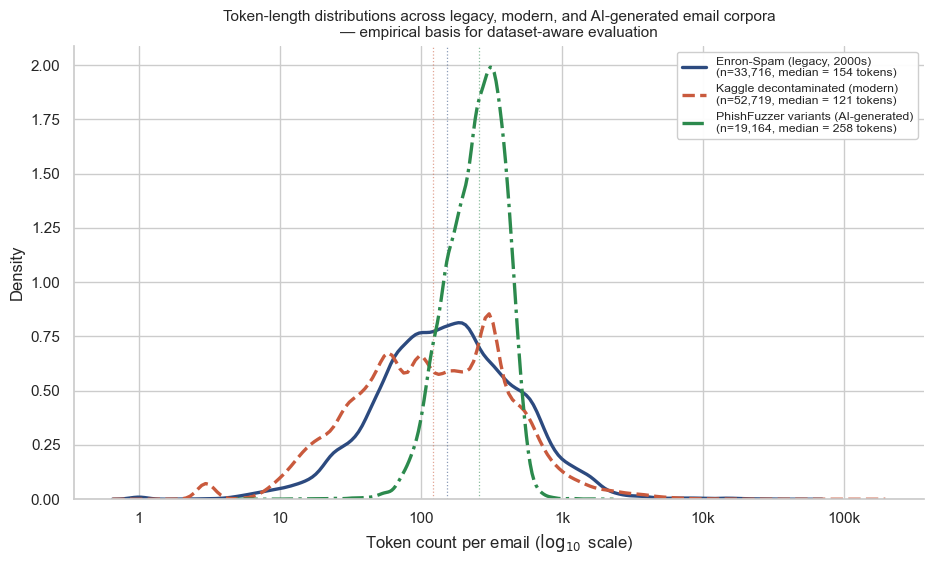


Per-stratum medians (preserving per-class detail for findings narrative):
                       stratum     n  median  p25  p75  p95
       Enron-Spam ham (legacy) 16545     176   74  373  962
      Enron-Spam spam (legacy) 17171     138   72  275  924
Modern legit (Kaggle decontam) 23804     199  108  382 1177
Modern phish (Kaggle decontam) 28915      62   31  244  540
     AI Valid (PhishFuzzer en)  6504     269  184  360  477
  AI Phishing (PhishFuzzer en)  6432     232  156  303  402
      AI Spam (PhishFuzzer en)  6228     283  194  384  510

Saved → figures\fig_cross_dataset_length.png


In [18]:
df_modern = df_phish_src[df_phish_src["source"] != "Enron"].copy()
df_modern["tok_len"] = df_modern["text"].str.split().str.len()

df_ai = df_phf[(df_phf["created_by"] == "LLM") & (df_phf["language"] == "en")].copy()
df_ai["tok_len"] = df_ai["text"].str.split().str.len()

print(f"Curve 1 — Enron-Spam (legacy):              {len(df_enron):>6,} rows")
print(f"Curve 2 — Kaggle decontaminated (modern):   {len(df_modern):>6,} rows  (expected 52,719)")
print(f"Curve 3 — PhishFuzzer variants, English:    {len(df_ai):>6,} rows  (expected ~19,164)")
print()

curves = [
    ("Enron-Spam (legacy, 2000s)",          df_enron["tok_len"],  "#2c4a7f", "-"),
    ("Kaggle decontaminated (modern)",      df_modern["tok_len"], "#c95a3d", "--"),
    ("PhishFuzzer variants (AI-generated)", df_ai["tok_len"],     "#2c8a4d", "-."),
]

fig, ax = plt.subplots(figsize=(9.5, 5.8))
for name, series, colour, ls in curves:
    s = series.dropna()
    s = s[s > 0]
    sns.kdeplot(
        np.log10(s), ax=ax,
        color=colour, linestyle=ls, linewidth=2.4,
        label=f"{name}\n(n={len(s):,}, median = {int(s.median())} tokens)",
        common_norm=False,
    )
    ax.axvline(np.log10(s.median()), color=colour, linestyle=":", linewidth=0.9, alpha=0.55)

ax.set_xlabel(r"Token count per email ($\log_{10}$ scale)")
ax.set_ylabel("Density")
ax.set_title(
    "Token-length distributions across legacy, modern, and AI-generated email corpora\n"
    "— empirical basis for dataset-aware evaluation",
    fontsize=11,
)
tick_locs = np.log10([1, 10, 100, 1000, 10_000, 100_000])
ax.set_xticks(tick_locs)
ax.set_xticklabels(["1", "10", "100", "1k", "10k", "100k"])
ax.legend(fontsize=8.8, loc="upper right", framealpha=0.95)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

out = FIGURES_DIR / "fig_cross_dataset_length.png"
plt.savefig(out)
plt.show()

# Per-stratum detail preserved alongside the 3-curve headline,
# so the "phishing-by-brevity" finding remains in the notebook record.
print()
print("Per-stratum medians (preserving per-class detail for findings narrative):")
rows = [
    ("Enron-Spam ham (legacy)",         df_enron.loc[df_enron.label == 0, "tok_len"]),
    ("Enron-Spam spam (legacy)",        df_enron.loc[df_enron.label == 1, "tok_len"]),
    ("Modern legit (Kaggle decontam)",  df_modern.loc[df_modern.label == 0, "tok_len"]),
    ("Modern phish (Kaggle decontam)",  df_modern.loc[df_modern.label == 1, "tok_len"]),
    ("AI Valid (PhishFuzzer en)",       df_ai.loc[df_ai["type_3class"] == "Valid",    "tok_len"]),
    ("AI Phishing (PhishFuzzer en)",    df_ai.loc[df_ai["type_3class"] == "Phishing", "tok_len"]),
    ("AI Spam (PhishFuzzer en)",        df_ai.loc[df_ai["type_3class"] == "Spam",     "tok_len"]),
]
table = []
for name, s in rows:
    s = s.dropna()
    s = s[s > 0]
    table.append({"stratum": name, "n": len(s), "median": int(s.median()),
                  "p25": int(s.quantile(0.25)), "p75": int(s.quantile(0.75)),
                  "p95": int(s.quantile(0.95))})
print(pd.DataFrame(table).to_string(index=False))
print(f"\nSaved → {out.relative_to(PROJECT_ROOT)}")

### 4.2 Pairwise top-token Jaccard overlap

A second sanity check on the domain shift: pairwise **Jaccard similarity** between
the top-500 non-stopword tokens of each corpus. Low overlap means the two sides
have different lexical profiles — i.e. a model trained on one and tested on the
other would not share vocabulary. With three corpora, this becomes a 3×3
triangle (3 pairwise scores).

In [19]:
def top_token_set(texts, n=500, drop_stopwords=True):
    counter = Counter()
    for t in texts:
        for tok in TOKEN_RX.findall(str(t).lower()):
            if drop_stopwords and tok in EN_STOPWORDS:
                continue
            counter[tok] += 1
    return {t for t, _ in counter.most_common(n)}

sets = {
    "Enron-Spam (legacy)":          top_token_set(df_enron["text"]),
    "Kaggle decontam (modern)":     top_token_set(df_modern["text"]),
    "PhishFuzzer variants (AI-en)": top_token_set(df_ai["text"]),
}

print("Pairwise Jaccard of top-500 non-stopword tokens:")
keys = list(sets.keys())
for i in range(len(keys)):
    for j in range(i + 1, len(keys)):
        a, b = sets[keys[i]], sets[keys[j]]
        jac = len(a & b) / len(a | b)
        print(f"  {keys[i]:<32s} ↔ {keys[j]:<32s} : {jac:.3f}  "
              f"(shared {len(a & b)}, only-left {len(a - b)}, only-right {len(b - a)})")

ai_unique_among_three = (sets["PhishFuzzer variants (AI-en)"]
                         - sets["Enron-Spam (legacy)"]
                         - sets["Kaggle decontam (modern)"])
legacy_unique_among_three = (sets["Enron-Spam (legacy)"]
                             - sets["Kaggle decontam (modern)"]
                             - sets["PhishFuzzer variants (AI-en)"])

print()
print(f"Tokens in AI top-500 but NOT in either legacy or modern top-500 "
      f"({len(ai_unique_among_three)}):")
print("  " + ", ".join(sorted(ai_unique_among_three)[:30]))
print()
print(f"Tokens in legacy top-500 but NOT in either modern or AI top-500 "
      f"({len(legacy_unique_among_three)}):")
print("  " + ", ".join(sorted(legacy_unique_among_three)[:30]))

Pairwise Jaccard of top-500 non-stopword tokens:
  Enron-Spam (legacy)              ↔ Kaggle decontam (modern)         : 0.351  (shared 260, only-left 240, only-right 240)
  Enron-Spam (legacy)              ↔ PhishFuzzer variants (AI-en)     : 0.250  (shared 200, only-left 300, only-right 300)
  Kaggle decontam (modern)         ↔ PhishFuzzer variants (AI-en)     : 0.263  (shared 208, only-left 292, only-right 292)

Tokens in AI top-500 but NOT in either legacy or modern top-500 (244):
  accounts, across, active, activity, advanced, ai, amazon, analysis, app, apple, appreciate, appreciated, approach, arrivals, articles, assist, associated, attention, automated, avoid, banking, benefits, border, bring, challenges, choosing, city, class, cloud, collection

Tokens in legacy top-500 but NOT in either modern or AI top-500 (192):
  accounting, act, adobe, advice, agreement, alias, america, amount, analyst, analysts, approved, april, assets, august, bankruptcy, big, bill, billion, board, bob, 

## 5. Summary table → `figures/table_dataset_summary.csv`

One-row-per-corpus-view dataset summary table per CLAUDE.md output spec.
PhishFuzzer is split into three rows (seeds / all variants / variants
English-only) so the cross-dataset filter applied in fig 3 is visible in
the table rather than buried in code.

Columns: Dataset, Source, Total emails, Positive class count, Imbalance ratio.
*Positive class* = `label == 1`. For PhishFuzzer this is Phishing | Spam
per Decision C2. Imbalance ratio is reported as **positive : negative**.

In [20]:
def _summarize(name, source, df):
    n = len(df)
    pos = int((df["label"] == 1).sum())
    neg = n - pos
    ratio = pos / neg if neg > 0 else float("inf")
    return {
        "Dataset": name,
        "Source": source,
        "Total emails": n,
        "Positive class count": pos,
        "Imbalance ratio (positive:negative)": f"{ratio:.3f} : 1",
    }

phf_variants = df_phf[df_phf["created_by"] == "LLM"]
phf_variants_en = phf_variants[phf_variants["language"] == "en"]
phf_seeds = df_phf[df_phf["created_by"] != "LLM"]

summary_rows = [
    _summarize(
        "Kaggle Phishing Email Dataset (full)",
        "Kaggle: naserabdullahalam/phishing-email-dataset",
        df_phish,
    ),
    _summarize(
        "Kaggle Phishing Email Dataset (decontaminated, Enron-removed; used in fig 3)",
        "Kaggle, with Enron.csv rows excluded",
        df_phish_clean,
    ),
    _summarize(
        "Enron-Spam (AUEB, Metsis et al. 2006; used in fig 3)",
        "http://www2.aueb.gr/users/ion/data/enron-spam/preprocessed/",
        df_enron,
    ),
    _summarize(
        "PhishFuzzer seeds (Tóth et al. 2025)",
        "GitHub: DataPhish/PhishFuzzer — seed templates",
        phf_seeds,
    ),
    _summarize(
        "PhishFuzzer variants (Tóth et al. 2025, all languages)",
        "GitHub: DataPhish/PhishFuzzer — LLM variants",
        phf_variants,
    ),
    _summarize(
        "PhishFuzzer variants (English only; used in fig 3)",
        "GitHub: DataPhish/PhishFuzzer — LLM variants, language == en",
        phf_variants_en,
    ),
]

summary_df = pd.DataFrame(summary_rows)
out = FIGURES_DIR / "table_dataset_summary.csv"
summary_df.to_csv(out, index=False)
print(summary_df.to_string(index=False))
print(f"\nSaved → {out.relative_to(PROJECT_ROOT)}")

                                                                     Dataset                                                       Source  Total emails  Positive class count Imbalance ratio (positive:negative)
                                        Kaggle Phishing Email Dataset (full)             Kaggle: naserabdullahalam/phishing-email-dataset         82486                 42891                           1.083 : 1
Kaggle Phishing Email Dataset (decontaminated, Enron-removed; used in fig 3)                         Kaggle, with Enron.csv rows excluded         52719                 28915                           1.215 : 1
                        Enron-Spam (AUEB, Metsis et al. 2006; used in fig 3)  http://www2.aueb.gr/users/ion/data/enron-spam/preprocessed/         33716                 17171                           1.038 : 1
                                        PhishFuzzer seeds (Tóth et al. 2025)               GitHub: DataPhish/PhishFuzzer — seed templates          3300         